In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

YearsOfExperience = np.random.randint(0, 19, size=500)

intercept = 60000
slope = (200000 - 60000) / (18 - 0)

noise = np.random.normal(0, 10000, size=500)

Salary = intercept + slope * YearsOfExperience + noise

Salary = np.clip(Salary, 60000, 200000)

df = pd.DataFrame({
    'YearsOfExperience': YearsOfExperience,
    'Salary': Salary
})

print(df.head())
print("Shape:", df.shape)

print("Minimum experience:", df['YearsOfExperience'].min())
print("Maximum experience:", df['YearsOfExperience'].max())

print("Minimum salary:", df['Salary'].min())
print("Maximum salary:", df['Salary'].max())



   YearsOfExperience         Salary
0                  6   99482.224454
1                 14  166754.417372
2                 10  140886.853434
3                  7  129198.006614
4                  6  115243.262899
Shape: (500, 2)
Minimum experience: 0
Maximum experience: 18
Minimum salary: 60000.0
Maximum salary: 200000.0


In [4]:

print("Shape:")
print(df.shape)

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCorrelation:")
print(df['YearsOfExperience'].corr(df['Salary']))


Shape:
(500, 2)

Summary Statistics:
       YearsOfExperience         Salary
count         500.000000     500.000000
mean            8.616000  127180.925269
std             5.662922   43794.340512
min             0.000000   60000.000000
25%             3.750000   88870.745175
50%             8.000000  124309.476989
75%            14.000000  166785.570406
max            18.000000  200000.000000

Missing Values:
YearsOfExperience    0
Salary               0
dtype: int64

Correlation:
0.9768203833752581


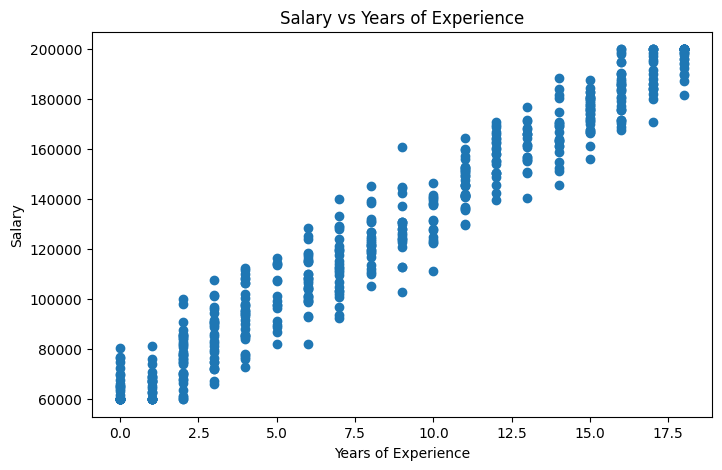

In [5]:

plt.figure(figsize=(8, 5))

plt.scatter(df['YearsOfExperience'], df['Salary'])

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Salary vs Years of Experience')

plt.show()


In [6]:

from google.colab import files

# Save the dataset as a CSV file
df.to_csv('dataset.csv', index=False)

# Download the CSV file to your computer
files.download('dataset.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from google.colab import files

df.to_csv("dataset.csv", index=False, sep=";")

files.download("dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

# Task 4: Split the dataset

from sklearn.model_selection import train_test_split

# Define X and y
X = df[['YearsOfExperience']]
y = df['Salary']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Display the size of each set
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (400, 1)
X_test shape: (100, 1)
y_train shape: (400,)
y_test shape: (100,)


In [9]:

# Task 5: Train Linear Regression

from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Get slope and intercept
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

# Calculate R2
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print("Training R2:", train_r2)
print("Test R2:", test_r2)


Slope: 7530.286219870034
Intercept: 62432.56011955148
Training R2: 0.9521361329733036
Test R2: 0.9615151545126538


In [10]:

# Task 6: Evaluate Linear Regression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict salaries on test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

# Display five actual and predicted salaries
print("\nFive Actual vs Predicted Salaries:")

for actual, predicted in zip(y_test.iloc[:5], y_pred[:5]):
    print("Actual:", round(actual, 2),
          "| Predicted:", round(predicted, 2))


MAE: 7150.900062645179
MSE: 79327938.06902076
RMSE: 8906.623269737009
R2: 0.9615151545126538

Five Actual vs Predicted Salaries:
Actual: 108075.67 | Predicted: 92553.7
Actual: 124220.08 | Predicted: 107614.28
Actual: 77629.26 | Predicted: 92553.7
Actual: 151185.25 | Predicted: 145265.71
Actual: 159031.63 | Predicted: 167856.57


In [11]:

# Task 7: Compare with a Baseline Model

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the baseline model
baseline = DummyRegressor(strategy="mean")

# Train the baseline model
baseline.fit(X_train, y_train)

# Predict salaries
baseline_pred = baseline.predict(X_test)

# Evaluate the baseline model
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

# Display results
print("Baseline MAE:", baseline_mae)
print("Baseline MSE:", baseline_mse)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

# Compare with Linear Regression
print("\nModel Comparison:")
print("Linear Regression R2:", r2_score(y_test, y_pred))
print("Baseline R2:", baseline_r2)


Baseline MAE: 39511.22901004637
Baseline MSE: 2062053107.2895904
Baseline RMSE: 45409.834918105465
Baseline R2: -0.00037637624836817096

Model Comparison:
Linear Regression R2: 0.9615151545126538
Baseline R2: -0.00037637624836817096


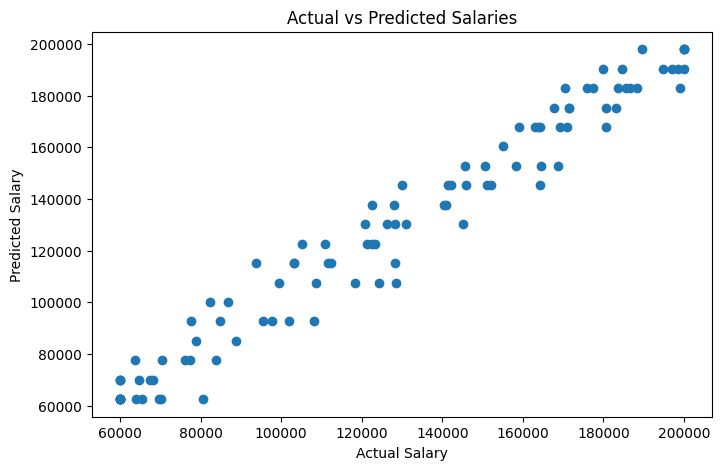

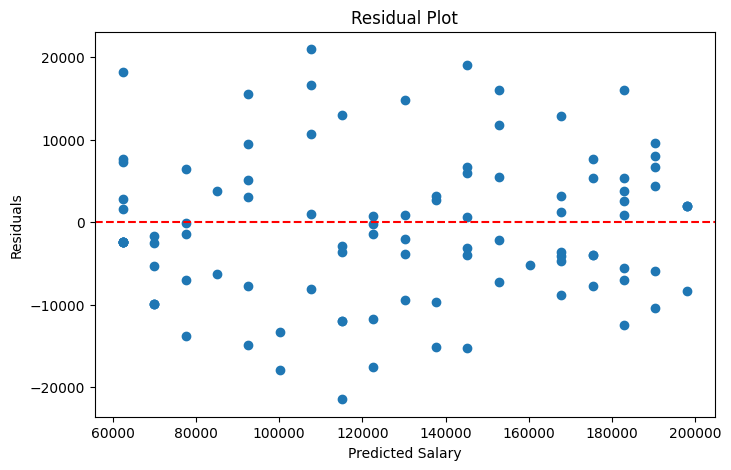

In [12]:
import matplotlib.pyplot as plt

# 1. Plot Actual vs Predicted
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salaries")

plt.show()


# 2. Calculate Residuals
residuals = y_test - y_pred


# 3. Plot Residuals
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [14]:
# Task 9: Predict New Salaries

import pandas as pd

# New experience values
new_experience = pd.DataFrame({
    "YearsOfExperience": [5, 10, 15]
})

# Predict salaries
new_predictions = model.predict(new_experience)

# Display predictions
for years, salary in zip(new_experience["YearsOfExperience"],
                         new_predictions):
    print("Experience:", years, "years",
          "| Predicted Salary:", round(salary, 2))

Experience: 5 years | Predicted Salary: 100083.99
Experience: 10 years | Predicted Salary: 137735.42
Experience: 15 years | Predicted Salary: 175386.85


In [15]:
# Task 10: Standardize the feature

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data
X_test_scaled = scaler.transform(X_test)

# Display results
print("Original X_train:")
print(X_train.head())

print("\nScaled X_train:")
print(X_train_scaled[:5])

print("\nScaled X_test:")
print(X_test_scaled[:5])

Original X_train:
     YearsOfExperience
249                 15
433                  6
19                   9
322                  0
332                  2

Scaled X_train:
[[ 1.14441709]
 [-0.45865743]
 [ 0.07570074]
 [-1.52737378]
 [-1.171135  ]]

Scaled X_test:
[[-0.81489621]
 [-0.45865743]
 [-0.81489621]
 [ 0.43193952]
 [ 0.9662977 ]]


In [16]:
# Task 11: Train Ridge Regression

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

# Ridge model with alpha = 10
ridge_10 = Ridge(alpha=10)
ridge_10.fit(X_train_scaled, y_train)

# Predictions
ridge_10_pred = ridge_10.predict(X_test_scaled)

# Evaluation
print("Ridge alpha=10")
print("Coefficient:", ridge_10.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, ridge_10_pred))
print("Test R2:", r2_score(y_test, ridge_10_pred))


# Ridge model with alpha = 100
ridge_100 = Ridge(alpha=100)
ridge_100.fit(X_train_scaled, y_train)

# Predictions
ridge_100_pred = ridge_100.predict(X_test_scaled)

# Evaluation
print("\nRidge alpha=100")
print("Coefficient:", ridge_100.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, ridge_100_pred))
print("Test R2:", r2_score(y_test, ridge_100_pred))


# Compare coefficients
print("\nCoefficient Comparison:")
print("Alpha 10:", ridge_10.coef_[0])
print("Alpha 100:", ridge_100.coef_[0])

Ridge alpha=10
Coefficient: 41245.48520283492
Test MAE: 7356.146278516028
Test R2: 0.9602805729967838

Ridge alpha=100
Coefficient: 33821.29786632463
Test MAE: 10916.931041125323
Test R2: 0.9185857332925474

Coefficient Comparison:
Alpha 10: 41245.48520283492
Alpha 100: 33821.29786632463


In [18]:
# Task 12: Train Lasso Regression

from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, r2_score

# Lasso model with alpha = 1000
lasso_1000 = Lasso(alpha=1000, max_iter=20000)
lasso_1000.fit(X_train_scaled, y_train)

lasso_1000_pred = lasso_1000.predict(X_test_scaled)

print("Lasso alpha=1000")
print("Coefficient:", lasso_1000.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, lasso_1000_pred))
print("Test R2:", r2_score(y_test, lasso_1000_pred))


# Lasso model with alpha = 10000
lasso_10000 = Lasso(alpha=10000, max_iter=20000)
lasso_10000.fit(X_train_scaled, y_train)

lasso_10000_pred = lasso_10000.predict(X_test_scaled)

print("\nLasso alpha=10000")
print("Coefficient:", lasso_10000.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, lasso_10000_pred))
print("Test R2:", r2_score(y_test, lasso_10000_pred))


# Lasso model with alpha = 50000
lasso_50000 = Lasso(alpha=50000, max_iter=20000)
lasso_50000.fit(X_train_scaled, y_train)

lasso_50000_pred = lasso_50000.predict(X_test_scaled)

print("\nLasso alpha=50000")
print("Coefficient:", lasso_50000.coef_[0])
print("Test MAE:", mean_absolute_error(y_test, lasso_50000_pred))
print("Test R2:", r2_score(y_test, lasso_50000_pred))


# Compare coefficients
print("\nCoefficient Comparison:")
print("Alpha 1000:", lasso_1000.coef_[0])
print("Alpha 10000:", lasso_10000.coef_[0])
print("Alpha 50000:", lasso_50000.coef_[0])

Lasso alpha=1000
Coefficient: 41276.62233290578
Test MAE: 7349.948481992414
Test R2: 0.9603341258800493

Lasso alpha=10000
Coefficient: 32276.622332905787
Test MAE: 12066.233096133028
Test R2: 0.9026705729204827

Lasso alpha=50000
Coefficient: 0.0
Test MAE: 39511.22901004637
Test R2: -0.00037637624836817096

Coefficient Comparison:
Alpha 1000: 41276.62233290578
Alpha 10000: 32276.622332905787
Alpha 50000: 0.0


In [19]:
# Task 13: Compare the Models

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create a comparison table
results = {
    "Model": [
        "Mean Baseline",
        "Linear Regression",
        "Ridge (alpha=10)",
        "Lasso (alpha=1000)"
    ],

    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, ridge_10_pred),
        mean_absolute_error(y_test, lasso_1000_pred)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_10_pred)),
        np.sqrt(mean_squared_error(y_test, lasso_1000_pred))
    ],

    "R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, y_pred),
        r2_score(y_test, ridge_10_pred),
        r2_score(y_test, lasso_1000_pred)
    ]
}

# Convert results into a DataFrame
comparison_df = pd.DataFrame(results)

# Display the table
print(comparison_df.round(4))

                Model         MAE        RMSE      R2
0       Mean Baseline  39511.2290  45409.8349 -0.0004
1   Linear Regression   7150.9001   8906.6233  0.9615
2    Ridge (alpha=10)   7356.1463   9048.3564  0.9603
3  Lasso (alpha=1000)   7349.9485   9042.2545  0.9603
